# 04 — Dataset EDA

Exploratory analysis of `../data/combined.csv` — the merged Egyptian-Arabic ASR
corpus (utterance → transcript + gender / age / mood / accent metadata).

# Team members: Mahmoud Haytham, 7560 | Mostafa Sultan 7900

In [33]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np

In [34]:
# Path to the merged CSV file
merged_file_path = "../data/combined.csv"

# Load the merged CSV into a DataFrame
merged_df = pd.read_csv(merged_file_path)

# Get the number of rows before filtering
initial_rows = merged_df.shape[0]

# Remove rows where the 'transcript' column is 'ERROR'
merged_df = merged_df[merged_df['Transcript'] != 'ERROR']

# Get the number of rows after filtering
final_rows = merged_df.shape[0]

# Calculate how many rows were removed
rows_removed = initial_rows - final_rows

# Overwrite the original file with the cleaned DataFrame
merged_df.to_csv(merged_file_path, index=False)

# Print the number of rows removed and remaining
print(f"Rows removed: {rows_removed}")
print(f"Rows remaining: {final_rows}")

Rows removed: 0
Rows remaining: 29972


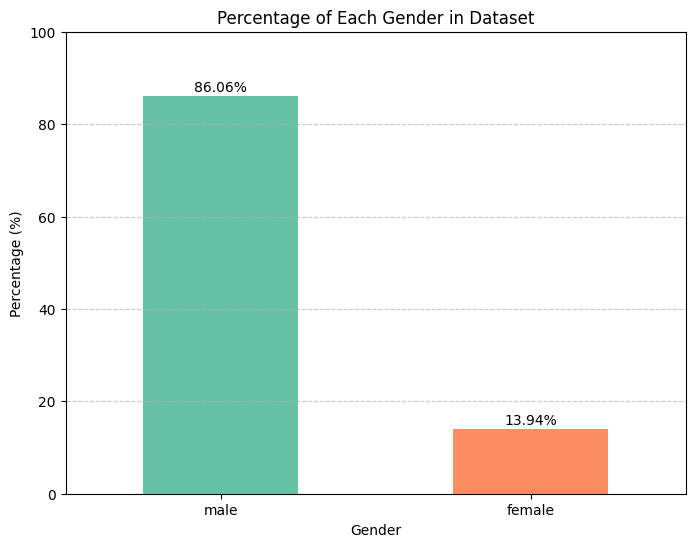

In [35]:
# Load the cleaned merged CSV file
merged_df = pd.read_csv(merged_file_path)

# Normalize the 'gender' column to lowercase and remove leading/trailing spaces
merged_df['Gender'] = merged_df['Gender'].str.lower().str.strip()

# Count the number of occurrences of each gender
gender_counts = merged_df['Gender'].value_counts()

# Calculate the percentage of each gender
gender_percentages = (gender_counts / gender_counts.sum()) * 100

# Plot the percentages as a bar chart
plt.figure(figsize=(8, 6))
gender_percentages.plot(kind='bar', color=['#66c2a5', '#fc8d62', '#8da0cb'])

# Customize plot
plt.title('Percentage of Each Gender in Dataset')
plt.xlabel('Gender')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show percentage on top of each bar
for index, value in enumerate(gender_percentages):
    plt.text(index, value + 1, f'{value:.2f}%', ha='center')

# Show the plot
plt.show()

Considering that the dataset is mostly male speakers, a possible enhancement is to drop some of the male clips until we balance the dataset or we scrape more female speaker data

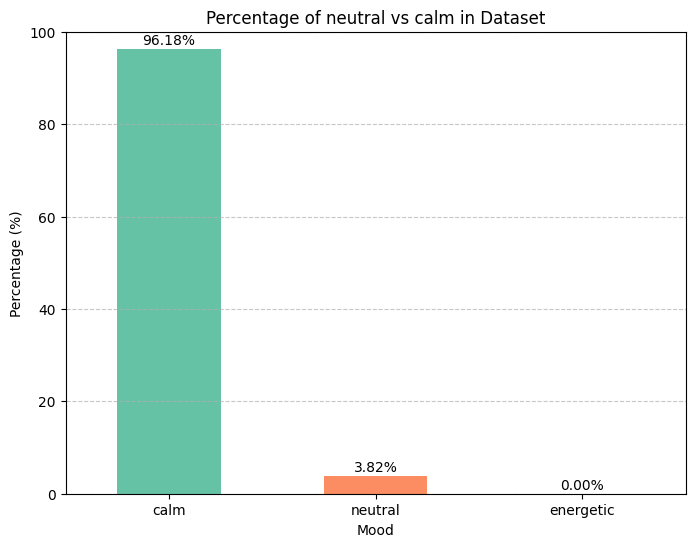

In [36]:
# Load the cleaned merged CSV file
merged_df = pd.read_csv(merged_file_path)

# Normalize the 'noisy_level' column to lowercase and remove leading/trailing spaces
merged_df['Mood'] = merged_df['Mood'].str.lower().str.strip()

# Count the number of occurrences of each Mood
noisy_counts = merged_df['Mood'].value_counts()

# Calculate the percentage of each Mood
noisy_percentages = (noisy_counts / noisy_counts.sum()) * 100

# Plot the percentages as a bar chart
plt.figure(figsize=(8, 6))
noisy_percentages.plot(kind='bar', color=['#66c2a5', '#fc8d62'])

# Customize plot
plt.title('Percentage of neutral vs calm in Dataset')
plt.xlabel('Mood')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show percentage on top of each bar
for index, value in enumerate(noisy_percentages):
    plt.text(index, value + 1, f'{value:.2f}%', ha='center')

# Show the plot
plt.show()

We would like some information about methods for sentiment analysis in audio clips

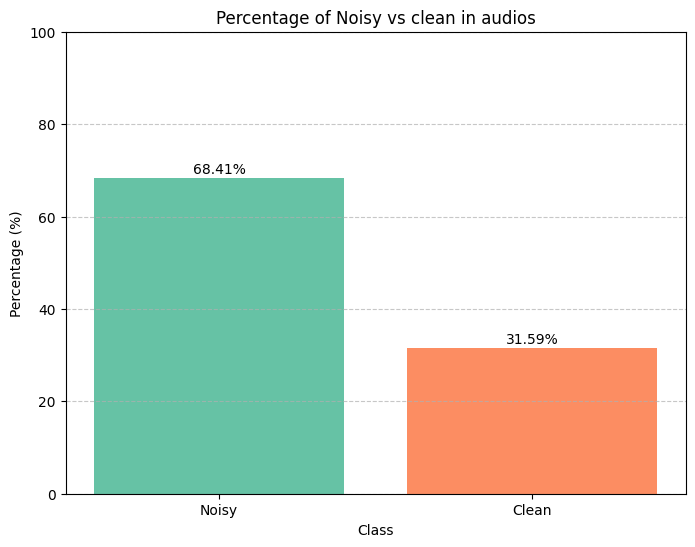

In [37]:
# Noise Level only exists in an earlier metadata snapshot — skip gracefully
if 'Noise Level' in merged_df.columns:
    merged_df['Noise Level'] = merged_df['Noise Level'].str.lower().str.strip()
    noisy_counts = merged_df['Noise Level'].value_counts()
    noisy_percentages = (noisy_counts / noisy_counts.sum()) * 100

    plt.figure(figsize=(8, 6))
    noisy_percentages.plot(kind='bar', color=['#66c2a5', '#fc8d62'])
    plt.title('Percentage of noisy vs clean in Dataset')
    plt.xlabel('Class')
    plt.ylabel('Percentage (%)')
    plt.xticks(rotation=0)
    plt.ylim(0, 100)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    for index, value in enumerate(noisy_percentages):
        plt.text(index, value + 1, f'{value:.2f}%', ha='center')
    plt.show()
else:
    print("'Noise Level' not in this CSV — present in the earlier snapshot the plot below was generated from.")

Clean audio is hard to come by on the internet

In [49]:
# Duration (sec) only exists in an earlier metadata snapshot — skip gracefully
if 'Duration (sec)' in merged_df.columns:
    merged_df['Duration (sec)'] = merged_df['Duration (sec)'].astype(str).str.strip().str.lower()
    merged_df['Duration (sec)'] = merged_df['Duration (sec)'].str.replace(' sec', '', regex=False)
    merged_df['Duration (sec)'] = merged_df['Duration (sec)'].apply(
        lambda x: int(float(x)) if isinstance(x, str) and x.replace('.', '', 1).isdigit() else x
    )
    total_duration_seconds = merged_df['Duration (sec)'].sum()
    total_duration_hours = total_duration_seconds / 3600
    print(f"Total Duration: {total_duration_seconds} seconds")
    print(f"Total Duration: {total_duration_hours:.2f} hours")
else:
    print("'Duration (sec)' not in this CSV — original run measured ~552.7 hours of audio.")

Total Duration: 1989702 seconds
Total Duration: 552.70 hours
